In [30]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

In [2]:
data = pd.read_csv("diabetes_progression_dataset.csv")

data.head()

,Age,Sex,BMI,Blood_Pressure,Serum_Measurement_1,Serum_Measurement_2,Serum_Measurement_3,Serum_Measurement_4,Serum_Measurement_5,Serum_Measurement_6,Disease_Progression
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


In [3]:
print("Dataset Shape:", data.shape)
print("\nColumn Names:")
print(data.columns)

print("\nDataset Information:")
data.info()

Dataset Shape: (442, 11)

Column Names:
Index(['Age', 'Sex', 'BMI', 'Blood_Pressure', 'Serum_Measurement_1',
       'Serum_Measurement_2', 'Serum_Measurement_3', 'Serum_Measurement_4',
       'Serum_Measurement_5', 'Serum_Measurement_6', 'Disease_Progression'],
      dtype='object')

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 442 entries, 0 to 441
Data columns (total 11 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Age                  442 non-null    float64
 1   Sex                  442 non-null    float64
 2   BMI                  442 non-null    float64
 3   Blood_Pressure       442 non-null    float64
 4   Serum_Measurement_1  442 non-null    float64
 5   Serum_Measurement_2  442 non-null    float64
 6   Serum_Measurement_3  442 non-null    float64
 7   Serum_Measurement_4  442 non-null    float64
 8   Serum_Measurement_5  442 non-null    float64
 9   Serum_Measurement_6  442 non-null 

In [4]:
# check missing value
print(data.isnull().sum())

Age                    0
Sex                    0
BMI                    0
Blood_Pressure         0
Serum_Measurement_1    0
Serum_Measurement_2    0
Serum_Measurement_3    0
Serum_Measurement_4    0
Serum_Measurement_5    0
Serum_Measurement_6    0
Disease_Progression    0
dtype: int64


In [5]:
data.describe()

,Age,Sex,BMI,Blood_Pressure,Serum_Measurement_1,Serum_Measurement_2,Serum_Measurement_3,Serum_Measurement_4,Serum_Measurement_5,Serum_Measurement_6,Disease_Progression
count,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,442.000000
mean,-7.284269e-18,2.348549e-17,-2.087320e-16,-4.571507e-17,-9.293722e-18,4.420798e-17,2.135044e-18,2.913707e-17,9.143013e-17,1.431736e-17,152.133484
std,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,77.093005
min,-1.072256e-01,-4.464164e-02,-9.027530e-02,-1.123988e-01,-1.267807e-01,-1.156131e-01,-1.023071e-01,-7.639450e-02,-1.260971e-01,-1.377672e-01,25.000000
25%,-3.729927e-02,-4.464164e-02,-3.422907e-02,-3.665608e-02,-3.424784e-02,-3.035840e-02,-3.511716e-02,-3.949338e-02,-3.324559e-02,-3.317903e-02,87.000000
50%,5.383060e-03,-4.464164e-02,-7.283766e-03,-5.670422e-03,-4.320866e-03,-3.819065e-03,-6.584468e-03,-2.592262e-03,-1.947171e-03,-1.077698e-03,140.500000
75%,3.807591e-02,5.068012e-02,3.124802e-02,3.564379e-02,2.835801e-02,2.984439e-02,2.931150e-02,3.430886e-02,3.243232e-02,2.791705e-02,211.500000
max,1.107267e-01,5.068012e-02,1.705552e-01,1.320436e-01,1.539137e-01,1.987880e-01,1.811791e-01,1.852344e-01,1.335973e-01,1.356118e-01,346.000000


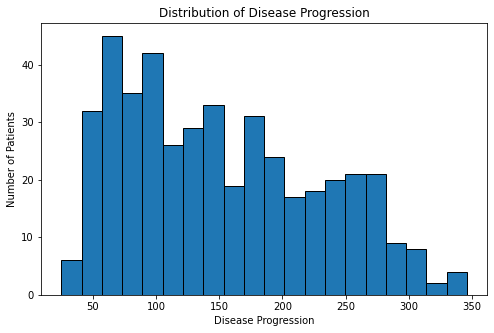

In [8]:
plt.figure(figsize=(8,5))

plt.hist(
    data["Disease_Progression"],
    bins=20,
    edgecolor="black"
)

plt.title("Distribution of Disease Progression")
plt.xlabel("Disease Progression")
plt.ylabel("Number of Patients")

plt.show()

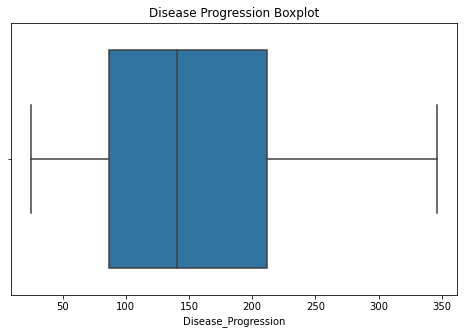

In [9]:
plt.figure(figsize=(8,5))

sns.boxplot(x=data["Disease_Progression"])

plt.title("Disease Progression Boxplot")

plt.show()

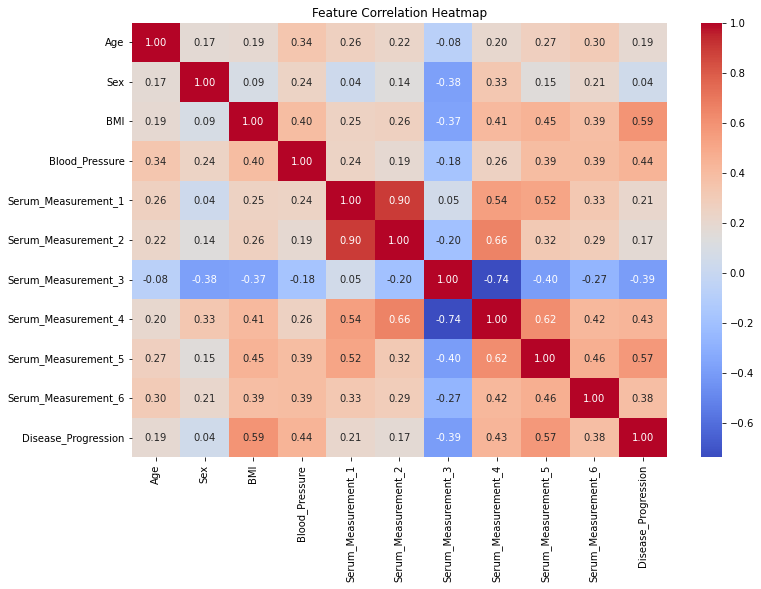

In [10]:
correlation = data.corr()

plt.figure(figsize=(12,8))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Feature Correlation Heatmap")

plt.show()

In [11]:
target_correlation = correlation["Disease_Progression"].sort_values(
    ascending=False
)

print(target_correlation)

Disease_Progression    1.000000
BMI                    0.586450
Serum_Measurement_5    0.565883
Blood_Pressure         0.441482
Serum_Measurement_4    0.430453
Serum_Measurement_6    0.382483
Serum_Measurement_1    0.212022
Age                    0.187889
Serum_Measurement_2    0.174054
Sex                    0.043062
Serum_Measurement_3   -0.394789
Name: Disease_Progression, dtype: float64


In [13]:
X = data.drop("Disease_Progression", axis=1)

y = data["Disease_Progression"]
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (353, 10)
Testing data: (89, 10)


In [15]:
model = LinearRegression()

model.fit(X_train, y_train)

print("Linear Regression Model Trained Successfully!")
y_pred = model.predict(X_test)

print(y_pred[:10])

Linear Regression Model Trained Successfully!
[139.5475584  179.51720835 134.03875572 291.41702925 123.78965872
  92.1723465  258.23238899 181.33732057  90.22411311 108.63375858]


In [16]:
r2 = r2_score(y_test, y_pred)

mae = mean_absolute_error(y_test, y_pred)

rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print("R² Score :", round(r2, 4))
print("MAE      :", round(mae, 4))
print("RMSE     :", round(rmse, 4))

R² Score : 0.4526
MAE      : 42.7941
RMSE     : 53.8534


In [24]:
feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": model.coef_
})

feature_importance["Absolute_Coefficient"] = (
    feature_importance["Coefficient"].abs()
)

feature_importance = feature_importance.sort_values(
    by="Absolute_Coefficient",
    ascending=False
)

print(feature_importance)

               Feature  Coefficient  Absolute_Coefficient
4  Serum_Measurement_1  -931.488846            931.488846
8  Serum_Measurement_5   736.198859            736.198859
2                  BMI   542.428759            542.428759
5  Serum_Measurement_2   518.062277            518.062277
3       Blood_Pressure   347.703844            347.703844
7  Serum_Measurement_4   275.317902            275.317902
1                  Sex  -241.964362            241.964362
6  Serum_Measurement_3   163.419983            163.419983
9  Serum_Measurement_6    48.670657             48.670657
0                  Age    37.904021             37.904021


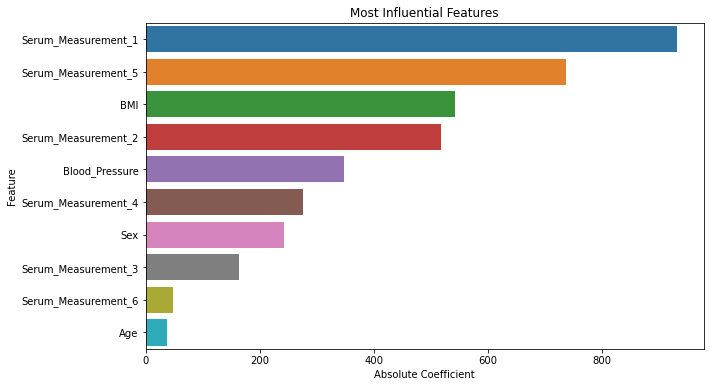

In [25]:
plt.figure(figsize=(10,6))

sns.barplot(
    data=feature_importance,
    x="Absolute_Coefficient",
    y="Feature"
)

plt.title("Most Influential Features")

plt.xlabel("Absolute Coefficient")
plt.ylabel("Feature")

plt.show()

In [19]:
comparison = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred
})

comparison.head(10)

,Actual,Predicted
0,219.0,139.547558
1,70.0,179.517208
2,202.0,134.038756
3,230.0,291.417029
4,111.0,123.789659
5,84.0,92.172347
6,242.0,258.232389
7,272.0,181.337321
8,94.0,90.224113
9,96.0,108.633759


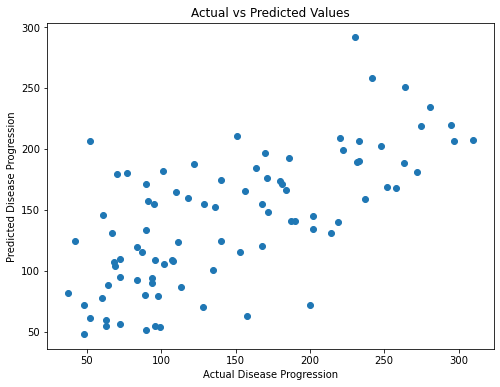

In [20]:
plt.figure(figsize=(8,6))

plt.scatter(y_test, y_pred)

plt.xlabel("Actual Disease Progression")
plt.ylabel("Predicted Disease Progression")

plt.title("Actual vs Predicted Values")

plt.show()

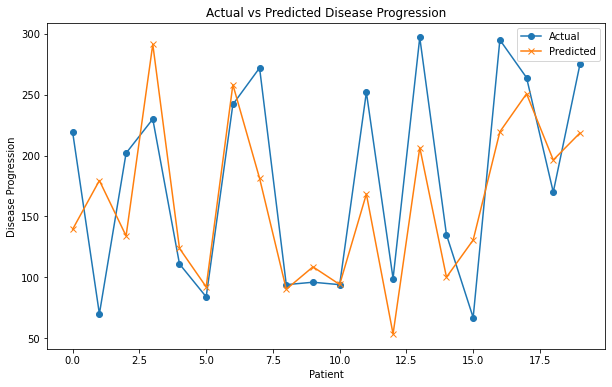

In [21]:
comparison_plot = comparison.head(20)

plt.figure(figsize=(10,6))

plt.plot(
    comparison_plot["Actual"].values,
    marker="o",
    label="Actual"
)

plt.plot(
    comparison_plot["Predicted"].values,
    marker="x",
    label="Predicted"
)

plt.xlabel("Patient")
plt.ylabel("Disease Progression")

plt.title("Actual vs Predicted Disease Progression")

plt.legend()

plt.show()

In [22]:
print("PROJECT CONCLUSION")
print("-------------------")
print("1. Diabetes dataset was successfully loaded.")
print("2. EDA was performed to understand the dataset.")
print("3. Feature correlations were analyzed.")
print("4. Linear Regression was trained.")
print("5. Model was evaluated using R², MAE and RMSE.")
print("6. Important features were identified using coefficients.")
print("7. Actual and predicted values were compared.")

PROJECT CONCLUSION
-------------------
1. Diabetes dataset was successfully loaded.
2. EDA was performed to understand the dataset.
3. Feature correlations were analyzed.
4. Linear Regression was trained.
5. Model was evaluated using R², MAE and RMSE.
6. Important features were identified using coefficients.
7. Actual and predicted values were compared.
